# 02. Quantitative phase analysis of a weighed 90/10 Al2O3/Si mixture

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sp8rks/Ceramic_Rietveld_Refinement/blob/main/scripted%20refinement%20%28rietx%29/02_Al2O3_Si_quantitative_phase_analysis.ipynb)


**Goal.** Measure the weight fractions in a mixture prepared as 90 wt% Al2O3 (corundum) and 10 wt% Si, using
the instrument profile from notebook 01 and `plan="lab_sample_refine"`, and compare with the existing GSAS-II
refinement of the same scan.

**Data.** `refinement examples/90Al2O3_10Si/`: `Al2O390_Si10.raw` (Bruker D2 Phaser, Cu Kα, 10 to 81° 2θ),
`Al2O3.cif`, `Si.cif`, and the GSAS-II result `refinement/test.lst`. Later we also use
`refinement examples/Al2O3_Si_SiO2/` and its GSAS-II refinement `test_amorphous.lst`.

**The teaching point.** rietx and GSAS-II agree with each other to about 0.1 wt%, and both say the mixture is
about 96.8 / 3.2 wt%, not 90 / 10. Two codes agreeing is not the same as being right. The second half of this
notebook works out *why* the Rietveld answer disagrees with the balance, and which explanations the data rule
in or out.

In [1]:
# Google Colab only: install rietx and fetch the workshop data. Running locally, this cell does nothing.
import os, subprocess, sys
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rietx[viz]==1.9.0"], check=True)
    if not os.path.isdir("/content/Ceramic_Rietveld_Refinement"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/sp8rks/Ceramic_Rietveld_Refinement.git",
                        "/content/Ceramic_Rietveld_Refinement"], check=True)
    os.chdir("/content/Ceramic_Rietveld_Refinement/scripted refinement (rietx)")
print("working directory:", os.path.basename(os.getcwd()))

working directory: scripted refinement (rietx)


In [2]:
from pathlib import Path
import warnings
import numpy as np
import matplotlib.pyplot as plt
import rietx as rx
from gsas_lst import read_lst
%matplotlib inline

# show warnings in full, without the temporary file path of the cell that raised them
warnings.formatwarning = lambda msg, cat, *args, **kw: f"{cat.__name__}: {msg}\n"

DATA = Path("../refinement examples/90Al2O3_10Si")
PATTERN = DATA / "Al2O390_Si10.raw"
WEIGHED = {"Al2O3": 90.0, "Si": 10.0}           # wt%, as prepared

def show_diagnostics(result):
    for d in result.diagnostics:
        print(f"[{d.level.upper()}] {d.code}  {', '.join(d.where)}")
        print("    ", d.message)

def load_structure():
    """Al2O3 + Si, joined into one Structure, with readable phase names."""
    al2o3, si = rx.Structure.from_cif(DATA / "Al2O3.cif"), rx.Structure.from_cif(DATA / "Si.cif")
    structure = rx.Structure(phases=[*al2o3.phases, *si.phases])
    structure.phases[0].name, structure.phases[1].name = "Al2O3", "Si"
    return structure

def wt(result):
    return {p.name: 100 * p.weight_fraction for p in result.qpa.phases}

print("rietx", rx.__version__)

rietx 1.9.0


## 1. The pattern, and a question about the instrument profile

Before reusing a calibration, check that it belongs to this instrument. The LaB6 profile from notebook 01 was
measured on a 250 mm goniometer (RAW v1 file, 2018). This scan comes from a Bruker D2 Phaser (RAW v4 file
written by DIFFRAC in 2021; the screenshot in the data folder shows the D2 software), whose goniometer radius
is 141 mm. Different instruments have different instrument functions. The quickest test is to compare peak
widths.

findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Failed to find font weight bold for DejaVu Sans, now using 400.


...

findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


findfont: Failed to find font weight bold for DejaVu Sans, now using 400.


findfont: Font family ['DejaVu Sans Mono'] not found. Falling back to DejaVu Sans.


{'format': 'bruker_raw', 'anode': 'Cu', 'wavelength': '1.54184', 'wavelength_alpha2': '1.54439'}


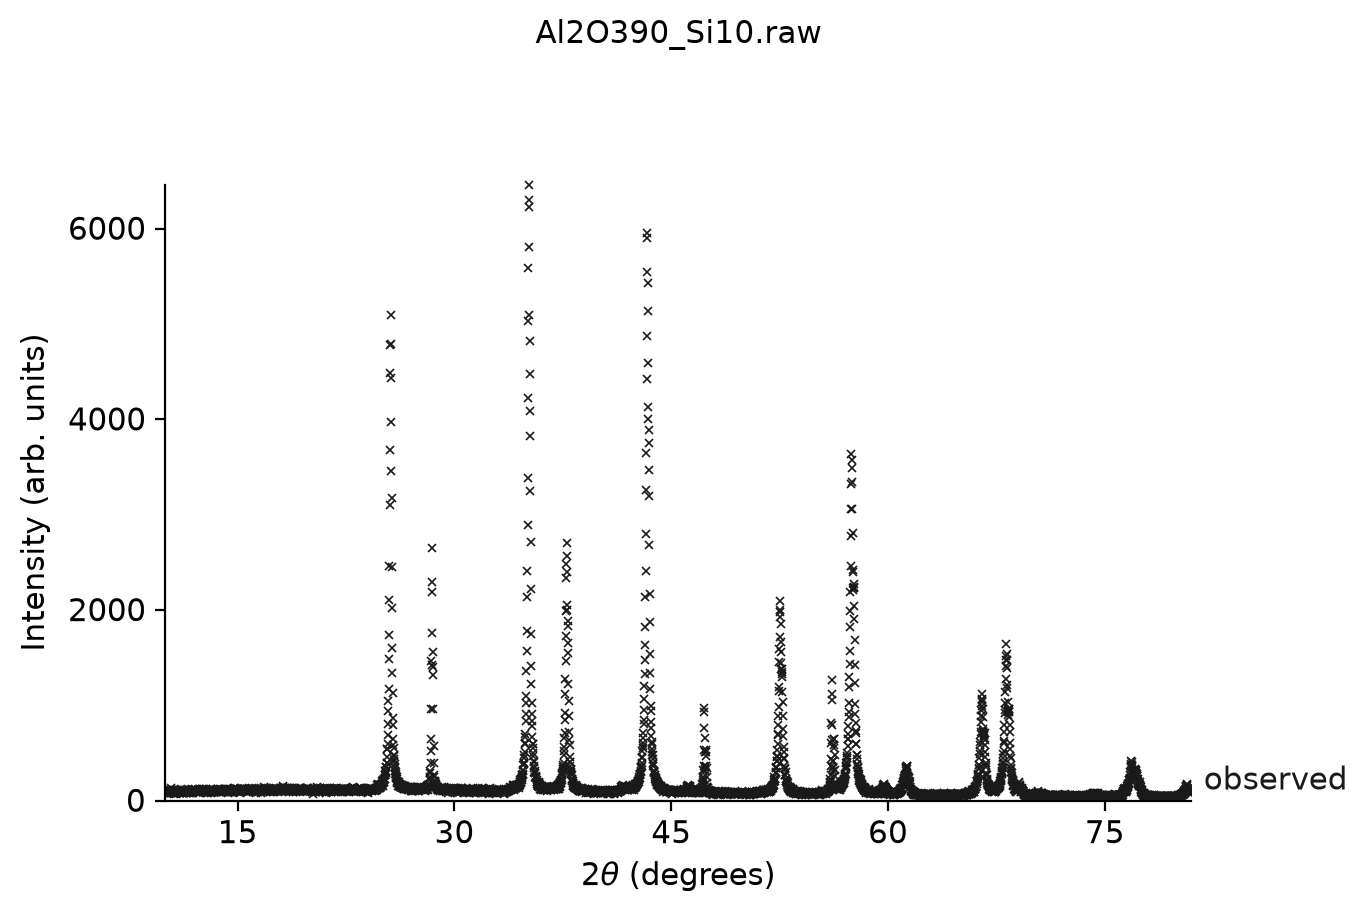

In [3]:
data = rx.read_pattern(PATTERN)
LIMITS = (float(min(data.two_theta)), float(max(data.two_theta)))
print({k: v for k, v in data.metadata.items() if k in ("format", "anode", "wavelength", "wavelength_alpha2")})
data.plot(title="Al2O390_Si10.raw", dpi=100)

In [4]:
lab6 = rx.read_pattern("../refinement examples/LaB6/LaB6_Jan2018.raw")
probe = rx.Instrument.bragg_brentano(radiation="CuKa")
def strongest(d, n):
    return sorted(rx.pick_peaks(d, probe).peaks, key=lambda p: -p.intensity)[:n]
print("LaB6, 250 mm instrument:", [(round(p.two_theta, 2), round(p.fwhm, 3)) for p in strongest(lab6, 6)])
print("This scan, D2 Phaser:   ", [(round(p.two_theta, 2), round(p.fwhm, 3)) for p in strongest(data, 12)])

LaB6, 250 mm instrument: [(30.4, 0.07), (48.97, 0.075), (37.45, 0.076), (21.36, 0.08), (67.56, 0.076), (54.0, 0.076)]


This scan, D2 Phaser:    [(43.33, 0.138), (35.13, 0.123), (57.48, 0.163), (25.56, 0.119), (25.56, 0.119), (52.52, 0.176), (37.75, 0.143), (68.16, 0.207), (68.18, 0.171), (68.16, 0.217), (66.47, 0.223), (28.44, 0.061)]


Si (111) at 28.44° is **0.061°** wide on the D2, narrower than any LaB6 line on the calibration instrument
(0.070 to 0.080°). The Al2O3 lines are 0.12 to 0.22° wide, so the corundum carries real sample broadening.

A calibrated instrument profile is a *lower bound* on every peak width, because `lab_sample_refine` can only
add sample broadening on top of it. If the profile is broader than the sharpest peaks, the fit cannot narrow
them, and it will say so. We load the profile as instructed, see what rietx reports, and then test whether
the mismatch matters for the number we want (the phase fractions).

## 2. `lab_sample_refine` with the LaB6 profile

In [5]:
instrument = rx.load_instrument_profile("lab_profile.json")
instrument.background = rx.auto_background(data, kind="chebyshev", two_theta_limits=LIMITS)
ref = rx.Refinement(load_structure(), instrument)
result = ref.fit(data, plan="lab_sample_refine", two_theta_limits=LIMITS)
print(result)

RefinementResult: converged (rietveld)
  stage scale_bkg: converged (2 evals, ftol=1e-06)
  stage disp: converged (16 evals, ftol=1e-06)
  stage cell: converged (24 evals, ftol=1e-06)
  stage sample_profile: converged (9 evals, ftol=1e-06)
  stage biso: converged (8 evals, ftol=1e-06)
  stage roughness: converged (5 evals, ftol=solver default), max|Δθ|/esd=0.000
  diagnostics: 5 unresolved
    WARNING FLOOR_HIT: phases.0.gauss_size refined to its floor (ρ=+0.139) — the data push this parameter below zero, where it cannot go. The usual reasons are a phase or term the data do not support, a width the instrument already supplies, or, for a displacement parameter, absorption or a wrong species or occupancy. Fix it at 0
    WARNING FLOOR_HIT: phases.0.gauss_strain refined to its floor (ρ=+0.119) — the data push this parameter below zero, where it cannot go. The usual reasons are a phase or term the data do not support, a width the instrument already supplies, or, for a displacement paramete

Reading the diagnostics:

* **`FLOOR_HIT` on every Si width term** (`lor_size`, `gauss_size`, `gauss_strain`) and on two of the Al2O3
  terms. The data push the sample broadening below zero, exactly as the width comparison predicted: the
  transferred instrument profile is already as broad as Si's peaks. So **no size or strain number from this
  fit means anything**, and `result.microstructure` should not be quoted.
* The `roughness` stage of the plan does nothing here, because no roughness model is declared.

Now the deliverable. For QPA, rietx's §4b says to read the fractions together with the background-absorption
check and any scale or ZMV code, never "Rwp stopped falling".

In [6]:
report = ref.report(plan="lab_sample_refine")
print(ref.summary(deliverable="qpa", report=report))

Refinement.summary: converged (rietveld)
  stage scale_bkg: converged (2 evals, ftol=1e-06)
  stage disp: converged (16 evals, ftol=1e-06)
  stage cell: converged (24 evals, ftol=1e-06)
  stage sample_profile: converged (9 evals, ftol=1e-06)
  stage biso: converged (8 evals, ftol=1e-06)
  stage roughness: converged (5 evals, ftol=solver default), max|Δθ|/esd=0.000
  diagnostics: 5 unresolved
    WARNING FLOOR_HIT: phases.0.gauss_size refined to its floor (ρ=+0.139) — the data push this parameter below zero, where it cannot go. The usual reasons are a phase or term the data do not support, a width the instrument already supplies, or, for a displacement parameter, absorption or a wrong species or occupancy. Fix it at 0
    WARNING FLOOR_HIT: phases.0.gauss_strain refined to its floor (ρ=+0.119) — the data push this parameter below zero, where it cannot go. The usual reasons are a phase or term the data do not support, a width the instrument already supplies, or, for a displacement parame

What the summary says:

* **Weight fractions: 96.8 ± 0.2 wt% Al2O3, 3.2 ± 0.2 wt% Si.** The esd is the fit's precision. It says nothing
  about accuracy, which is the subject of the rest of this notebook.
* **Background absorption**: the background can mimic at most 16 % of any structural parameter (an O Biso),
  under the 25 % at which `BACKGROUND_ABSORPTION` fires. The fractions are not being bent by the background.
* **Layer 1 abstained** (`unreadable`): too little of the misfit sits in regions the linear attribution can
  read. We fall back on Layer 0, the regions themselves.
* **Durbin-Watson 0.84, esds inflated ×3**: the residual is serially correlated; quote esds with that caveat.
* The single worst region, **55.9 to 56.4°, carries 21 % of χ²**. That is Si (311).

 region (deg)     χ² share   local Rwp   max |Δ|/σ
  55.90- 56.41     0.211      0.424      19.1
  47.16- 47.56     0.062      0.278      10.3
  43.00- 43.59     0.051      0.078       8.2
  25.44- 25.78     0.047      0.099      11.6
  28.30- 28.66     0.038      0.145      10.0
  57.33- 57.81     0.030      0.073       5.6


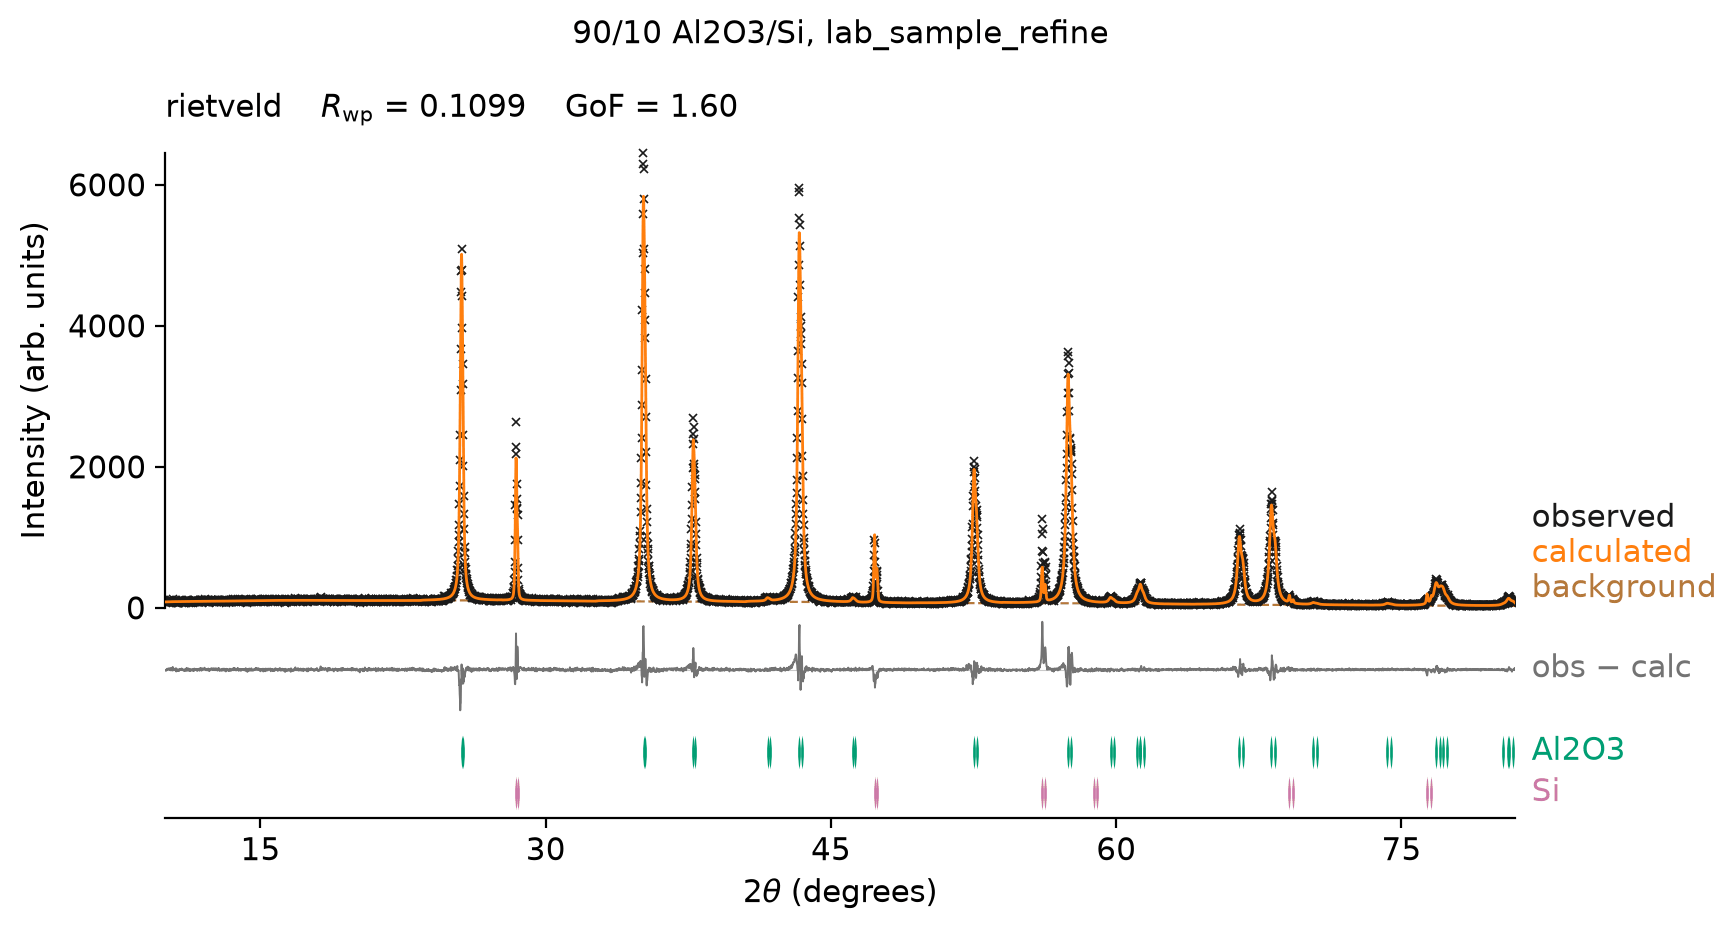

In [7]:
print(" region (deg)     χ² share   local Rwp   max |Δ|/σ")
for r in report.regions[:6]:
    print(f" {r.two_theta_lo:6.2f}-{r.two_theta_hi:6.2f}   {r.chi2_share:7.3f}    {r.local_rwp:7.3f}    {r.max_abs_delta_over_sigma:6.1f}")
rx.viz.plot_result(result, figsize=(10, 4.5), dpi=110, title="90/10 Al2O3/Si, lab_sample_refine")

## 3. Side by side with GSAS-II

The GSAS-II refinement in the repository used its own instrument parameters, refined U, V, W, X, Y and SH/L
on this pattern, and refined Uiso for every atom.

In [8]:
gsas = read_lst(DATA / "refinement" / "test.lst")
g_al, g_si = gsas["phases"]["Al2 O3"], gsas["phases"]["Si"]
v = {p.path: p for p in result.parameters}
s = result.statistics
biso = lambda u: 8 * np.pi**2 * u
rows = [
    ("Al2O3 (wt%)", f"{wt(result)['Al2O3']:.2f}", f"{100*g_al['weight_fraction']:.2f}"),
    ("Si (wt%)", f"{wt(result)['Si']:.2f}", f"{100*g_si['weight_fraction']:.2f}"),
    ("Al2O3 a (Å)", f"{v['phases.0.cell.a'].value:.5f}", f"{g_al['a']:.5f}"),
    ("Al2O3 c (Å)", f"{v['phases.0.cell.c'].value:.5f}", f"{g_al['c']:.5f}"),
    ("Si a (Å)", f"{v['phases.1.cell.a'].value:.5f}", f"{g_si['a']:.5f}"),
    ("Biso O, Al (Å²)", f"{v['phases.0.atoms.0.biso'].value:.2f}, {v['phases.0.atoms.1.biso'].value:.2f}",
     f"{biso(g_al['uiso']['O1']):.2f}, {biso(g_al['uiso']['Al1']):.2f}"),
    ("Biso Si (Å²)", f"{v['phases.1.atoms.0.biso'].value:.2f}", f"{biso(g_si['uiso']['Si']):.2f}"),
    ("GoF", f"{s.gof:.2f}", f"{gsas['gof']:.2f}"),
    ("Durbin-Watson", f"{s.durbin_watson:.2f}", f"{gsas['durbin_watson']:.3f}"),
    ("weighed (wt%)", "90 / 10", "90 / 10"),
]
print(f"{'':18s}{'rietx':>16s}{'GSAS-II':>16s}")
for name, a, b in rows:
    print(f"{name:18s}{a:>16s}{b:>16s}")

                             rietx         GSAS-II
Al2O3 (wt%)                  96.84           96.76
Si (wt%)                      3.16            3.24
Al2O3 a (Å)                4.76340         4.76178
Al2O3 c (Å)               13.00309        12.99872
Si a (Å)                   5.43402         5.43210
Biso O, Al (Å²)         2.52, 2.88      4.01, 3.82
Biso Si (Å²)                  2.60            3.01
GoF                           1.60            1.76
Durbin-Watson                 0.84           0.726
weighed (wt%)              90 / 10         90 / 10


The two codes agree on the fractions to about 0.1 wt%, on the cells to a few parts in 10⁴, and on fit quality.
They also agree on something worth noticing: **both refine displacement parameters far too large**, Biso
around 2.5 to 4 Å² for corundum and Si, where room-temperature values are about 0.2 to 0.5 Å². Since a phase's
intensity goes as scale × exp(−2B s²), B and scale trade, so this matters for QPA. We test it below.

## 4. Is the answer stable under the choices we made?

rietx's QPA rule: fractions must be stable when the analysis choices change. Three changes:

1. **Background**: P-spline instead of Chebyshev.
2. **Instrument**: drop the LaB6 profile entirely. Refine the instrument widths on this pattern, using Si as the
   internal width standard (Si sample broadening held at zero, Al2O3 broadening free), with the D2's 141 mm
   radius.
3. **Displacement parameters**: hold Biso at typical room-temperature values (O 0.30, Al 0.25, Si 0.47 Å²)
   instead of refining them.

In [9]:
def fit_with_profile(background="chebyshev", hold_b=None):
    inst = rx.load_instrument_profile("lab_profile.json")
    inst.background = rx.auto_background(data, kind=background, two_theta_limits=LIMITS)
    r = rx.Refinement(load_structure(), inst)
    if hold_b:
        r.set_values(hold_b); r.hold(list(hold_b))
    return r, r.fit(data, plan="lab_sample_refine", two_theta_limits=LIMITS)

def fit_self_calibrated():
    inst = rx.Instrument.bragg_brentano(radiation="CuKa", goniometer_radius_mm=141.0)
    inst.background = rx.auto_background(data, kind="chebyshev", two_theta_limits=LIMITS)
    h = float(np.median([p.fwhm for p in strongest(data, 12)]))
    inst.profile.w.value, inst.profile.x.value = (0.6 * h) ** 2, 0.6 * h
    plan = rx.RefinementPlan(stages=[
        rx.Stage(name="scale_bkg", turn_on=["phases.*.scale", "instrument.background.*"]),
        rx.Stage(name="zero", turn_on=["instrument.zero_shift"]),
        rx.Stage(name="cell", turn_on=["phases.*.cell.*"]),
        rx.Stage(name="profile_w", turn_on=["instrument.profile.w"]),
        rx.Stage(name="profile", turn_on=["instrument.profile.u", "instrument.profile.v",
                                          "instrument.profile.x", "instrument.profile.y"]),
        rx.Stage(name="al2o3_broadening", turn_on=["phases.0.lor_size", "phases.0.lor_strain"]),
        rx.Stage(name="biso", turn_on=["phases.*.atoms.*.biso"]),
    ])
    r = rx.Refinement(load_structure(), inst)
    return r, r.fit(data, plan=plan, two_theta_limits=LIMITS)

LITERATURE_B = {"phases.0.atoms.0.biso": 0.30, "phases.0.atoms.1.biso": 0.25, "phases.1.atoms.0.biso": 0.47}
variants = {
    "LaB6 profile, Chebyshev (above)": (ref, result),
    "LaB6 profile, P-spline": fit_with_profile("pspline"),
    "self-calibrated on this pattern": fit_self_calibrated(),
    "LaB6 profile, Biso held": fit_with_profile(hold_b=LITERATURE_B),
}
print(f"{'':34s}{'Al2O3':>8s}{'Si':>7s}{'GoF':>7s}   new diagnostic codes")
seen = {d.code for d in result.diagnostics}
for name, (r, res) in variants.items():
    w = wt(res)
    new = sorted({d.code for d in res.diagnostics} - seen)
    print(f"{name:34s}{w['Al2O3']:8.2f}{w['Si']:7.2f}{res.statistics.gof:7.2f}   {new}")

                                     Al2O3     Si    GoF   new diagnostic codes
LaB6 profile, Chebyshev (above)      96.84   3.16   1.60   []
LaB6 profile, P-spline               96.82   3.18   1.61   []
self-calibrated on this pattern      96.83   3.17   1.52   ['CONSTRAINT_ACTIVE', 'RESOLUTION_NOT_POSITIVE', 'RESOLUTION_UNCONSTRAINED']
LaB6 profile, Biso held              96.38   3.62   2.49   ['HOLD_BLOCKED_PLAN']


* **Background and instrument choice move the fractions by less than 0.05 wt%.** Even dropping the LaB6
  calibration for a self-calibrated profile changes nothing that matters. The self-calibrated fit does raise
  `RESOLUTION_UNCONSTRAINED` and `RESOLUTION_NOT_POSITIVE`: refining U, V, W on a pattern dominated by
  Lorentzian width gives resolution terms that are not measurements. That is rietx telling you not to quote
  those widths, which we do not; we only use the fit as a cross-check on the fractions.
* **Holding Biso at physical values moves Si by about +0.5 wt%** (to about 3.6 %) and makes the fit worse
  (GoF 1.6 → 2.5). Something in this specimen depresses high-angle intensity in both phases, and the free B
  absorbs it. That is an unresolved systematic of about 0.5 wt%, five times larger than the agreement between
  the two codes, but still nowhere near the 6.8 wt% gap to the weighed composition.

So the 3.2 wt% is robust to how we model the pattern. Whatever is wrong is in the specimen or its preparation.

## 5. Why does the Rietveld answer disagree with the balance?

Three candidates are usually named: **amorphous content**, **microabsorption**, and **particle statistics**.
They leave different fingerprints, and the data can tell them apart.

### 5a. Amorphous content: the arithmetic rules it out

Rietveld QPA normalises the *crystalline* phases to 100 %. Treat the weighed Si as an internal standard (the
usual way to measure amorphous content): if the true Si fraction is S and Rietveld reports R_Si, the
crystalline mass is S / R_Si of the sample, and the amorphous fraction is 1 − S / R_Si.

In [10]:
S = WEIGHED["Si"] / 100
for name, R in [("rietx", wt(result)["Si"] / 100), ("GSAS-II", g_si["weight_fraction"])]:
    print(f"{name:8s} R_Si = {R:.4f}  ->  amorphous fraction = 1 - S/R_Si = {1 - S / R:+.2f}")
crystalline_si = (wt(result)["Si"] / wt(result)["Al2O3"]) / (S / (1 - S))
print(f"For Si to read this low through non-diffracting Si, only {100*crystalline_si:.0f} % of the Si mass could be crystalline.")

rietx    R_Si = 0.0316  ->  amorphous fraction = 1 - S/R_Si = -2.17
GSAS-II  R_Si = 0.0324  ->  amorphous fraction = 1 - S/R_Si = -2.09
For Si to read this low through non-diffracting Si, only 29 % of the Si mass could be crystalline.


The internal-standard formula gives an amorphous content of about **−200 %**, which is impossible. Amorphous
material anywhere *other* than the Si (an amorphous fraction in the alumina, for example) adds mass that does
not diffract, so it would make Si read **higher** than 10 %, not lower. The only way amorphous content lowers
the Si reading is for about two-thirds of the Si powder itself to be non-diffracting. Commercial micron-sized
Si carries a native oxide a few nanometres thick, which is far too little. Amorphous content is ruled out as
the main cause.

### 5b. Particle statistics: the fingerprint is in the individual Si reflections

Microabsorption and amorphous content scale **every** Si reflection by the same factor, which the fit absorbs
into the Si scale: the fit stays good and the fraction is wrong. Poor particle statistics (too few large Si
grains in the irradiated volume) instead make each reflection's intensity a lottery, so the
**reflection-to-reflection** ratio of observed to calculated intensity scatters.

To measure that ratio, we compute the pattern with the Si scale set to zero, subtract it from the observed
counts, and integrate what is left over each Si reflection, against the calculated Si intensity over the same
window. The counting error of each ratio comes from the observed σ. Si (222) is skipped: it is forbidden in
the diamond structure, so its calculated intensity is zero.

In [11]:
def si_reflection_ratios(r, res, phase_index=1, phase_name="Si"):
    tt = np.asarray(res.two_theta); yobs = np.asarray(res.y_obs); ycalc = np.asarray(res.y_calc)
    sig = np.asarray(res.sigma)
    path = f"phases.{phase_index}.scale"
    scale = next(p.value for p in r.parameters() if p.path == path)
    r.set_values({path: 0.0}); y_other = np.asarray(r.predict(tt)); r.set_values({path: scale})
    y_si = ycalc - y_other
    seen, out = set(), []
    for pos, hkl in sorted(zip(res.ticks[phase_name], res.tick_hkl[phase_name])):
        if tuple(hkl) in seen:        # each hkl appears once per emission line; keep the Kα1 one
            continue
        seen.add(tuple(hkl))
        m = (tt > pos - 0.35) & (tt < pos + 0.45)   # covers Kα1 and Kα2
        obs, calc = (yobs - y_other)[m].sum(), y_si[m].sum()
        if calc < 1e-3 * y_si.sum():  # (222) is forbidden in the diamond structure: nothing calculated
            continue
        out.append((tuple(hkl), pos, obs / calc, np.sqrt((sig[m] ** 2).sum()) / calc))
    return out

ratios = si_reflection_ratios(ref, result)
print(" hkl         2θ      obs/calc   counting error")
for hkl, pos, q, e in ratios:
    print(f" {str(hkl):10s}{pos:6.2f}    {q:6.2f}      ± {e:.2f}")

 hkl         2θ      obs/calc   counting error
 (1, 1, 1)  28.45      1.07      ± 0.01
 (2, 2, 0)  47.30      0.82      ± 0.01
 (3, 1, 1)  56.11      2.15      ± 0.02
 (4, 0, 0)  69.11      1.11      ± 0.07
 (3, 3, 1)  76.35      0.62      ± 0.05


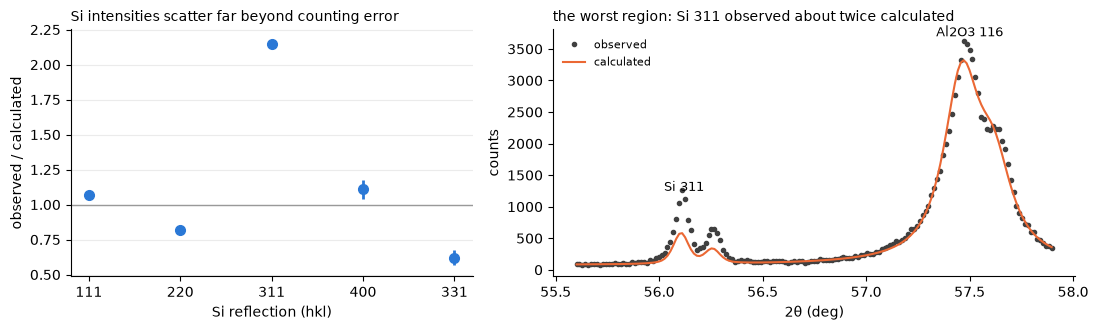

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.3]})
labels = ["".join(map(str, h)) for h, *_ in ratios]
q = np.array([x[2] for x in ratios]); e = np.array([x[3] for x in ratios])
ax = axes[0]
ax.errorbar(range(len(q)), q, yerr=e, fmt="o", ms=7, color="#2a78d6", lw=2, capsize=0)
ax.axhline(1, color="0.6", lw=1)
ax.set_xticks(range(len(q)), labels); ax.set_xlabel("Si reflection (hkl)")
ax.set_ylabel("observed / calculated"); ax.set_title("Si intensities scatter far beyond counting error", fontsize=10, loc="left")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, axis="y")
ax = axes[1]
tt = np.asarray(result.two_theta); m = (tt > 55.6) & (tt < 57.9)
ax.plot(tt[m], np.asarray(result.y_obs)[m], "o", ms=3, color="0.25", label="observed")
ax.plot(tt[m], np.asarray(result.y_calc)[m], color="#eb6834", lw=1.5, label="calculated")
ax.annotate("Si 311", (56.12, 1250), ha="center", fontsize=9); ax.annotate("Al2O3 116", (57.5, 3700), ha="center", fontsize=9)
ax.set_xlabel("2θ (deg)"); ax.set_ylabel("counts"); ax.legend(frameon=False, fontsize=8)
ax.set_title("the worst region: Si 311 observed about twice calculated", fontsize=10, loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

Si (311) is observed at about **twice** its calculated intensity while (331) is at about two-thirds and (220)
at about four-fifths. The counting errors are a few percent, so this scatter is real. It is not a structural
error either: silicon's structure is about as certain as a structure gets. It is the signature of **poor particle
statistics**: a few large, randomly oriented Si grains, each contributing strongly to whichever reflection it
happens to satisfy. The scan's screenshot in the data folder shows the specimen was **not spun** (rotation
0 /min), which makes this much worse.

What this does to the fraction: with a handful of grains, the integrated Si intensity is a random draw, and the
mean of a few reflections can sit well below the true value. A factor of three is a lot, but not impossible
with coarse Si in a static flat plate. **Particle statistics is the leading explanation the data support**, and
it is testable: spin the specimen, grind or sieve the Si finer, and remeasure several independent mounts.
Their fractions will scatter if this is right.

### 5c. Microabsorption: real, but too small here

Brindley's correction depends on the difference between each phase's linear absorption coefficient and the
mixture's, times the particle radius. rietx computes the µ values from composition and density. We try Si
particles of 5, 20 and 50 µm radius in 1 µm alumina.

In [13]:
def fit_brindley(r_si_um, r_al_um=1.0):
    structure = load_structure()
    structure.phases[0].particle_radius_um = r_al_um
    structure.phases[1].particle_radius_um = r_si_um
    inst = rx.load_instrument_profile("lab_profile.json")
    inst.background = rx.auto_background(data, kind="chebyshev", two_theta_limits=LIMITS)
    return rx.Refinement(structure, inst).fit(data, plan="lab_sample_refine", two_theta_limits=LIMITS)

print(f"{'R_Si (µm)':>10s}{'µ_Si (1/cm)':>13s}{'µ_Al2O3':>9s}{'µR_Si':>8s}{'Si wt% corrected':>18s}   codes")
for r_si in (5, 20, 50):
    res_b = fit_brindley(r_si)
    al, si = res_b.qpa.phases
    codes = sorted({d.code for d in res_b.diagnostics if "BRINDLEY" in d.code or "MICRO" in d.code})
    print(f"{r_si:10d}{si.mu_cm:13.1f}{al.mu_cm:9.1f}{si.mu_r:8.3f}{100*si.weight_fraction_corrected:18.2f}   {codes}")
print("uncorrected Si wt%:", round(wt(result)["Si"], 2))

 R_Si (µm)  µ_Si (1/cm)  µ_Al2O3   µR_Si  Si wt% corrected   codes


         5        151.5    125.5   0.076              3.22   ['BRINDLEY_OUTSIDE_REGIME']


        20        151.5    125.5   0.303              3.39   ['BRINDLEY_OUTSIDE_REGIME']


        50        151.5    125.5   0.758              3.77   ['BRINDLEY_OUTSIDE_REGIME']
uncorrected Si wt%: 3.16


For Cu Kα, Si (µ ≈ 152 cm⁻¹) and corundum (µ ≈ 125 cm⁻¹) absorb about equally, so the correction is small:
even 50 µm Si particles move Si only from 3.2 to 3.8 wt%. `BRINDLEY_OUTSIDE_REGIME` also fires: µR
above 0.05 is outside the range where Brindley's model is derived, and the round-robin literature found that
applying it there can make results worse. **Microabsorption cannot turn 10 wt% into 3 wt% in this mixture.**

### 5d. What is left on the list

* **Weighing, mixing and segregation.** Si (2.33 g/cm³) and corundum (3.99 g/cm³) can segregate in a loosely
  mixed or tapped powder, and a flat-plate mount samples only the top tens of micrometres. This cannot be
  tested from the pattern; it is tested by preparing and measuring replicate mounts.
* **The displacement-parameter systematic** from section 4 (about 0.5 wt%).

## 6. The Al2O3/Si/SiO2 sample: is there amorphous content to see?

The `Al2O3_Si_SiO2` scan was measured on the same D2 Phaser and refined in GSAS-II as `test_amorphous`. Its
weighed composition is not recorded in the repository, so it cannot calibrate an amorphous content. It does
teach something: fit it with the phases we expect and let rietx's report say what is missing.

GoF 3.53, DW 0.18; fractions: {'Al2O3': 86.7, 'Si': 13.3}
suggested: add_impurity_phase (confidence 0.90): 31 observed peak(s) have no calculated reflection nearby and are not accounted for by the peak-position evidence, the strongest at 30.520° at 23σ.  If the extra lines are an unknown phase rather than ...
suggested: increase_background_flexibility (confidence 0.60): between the peak regions the residual is systematic rather than noise: χ²_red=4.4 over 3868 channels (27% of total χ²) at Durbin-Watson d=0.51 (2 = uncorrelated).  Layer 0's regions are peak clusters,...
suggested: reindex_or_recheck_cell (confidence 0.40): 10 of 13 misfitting region(s), carrying 9% of χ², have peak offsets beyond the linearisation radius (0.4·FWHM; the worst measures ≥7.0×FWHM — a lower bound, the saturated linear fit cannot see further...
55 unmatched observed points, in clusters around: [28, 30, 31, 32, 35, 36, 50, 51, 60, 61]


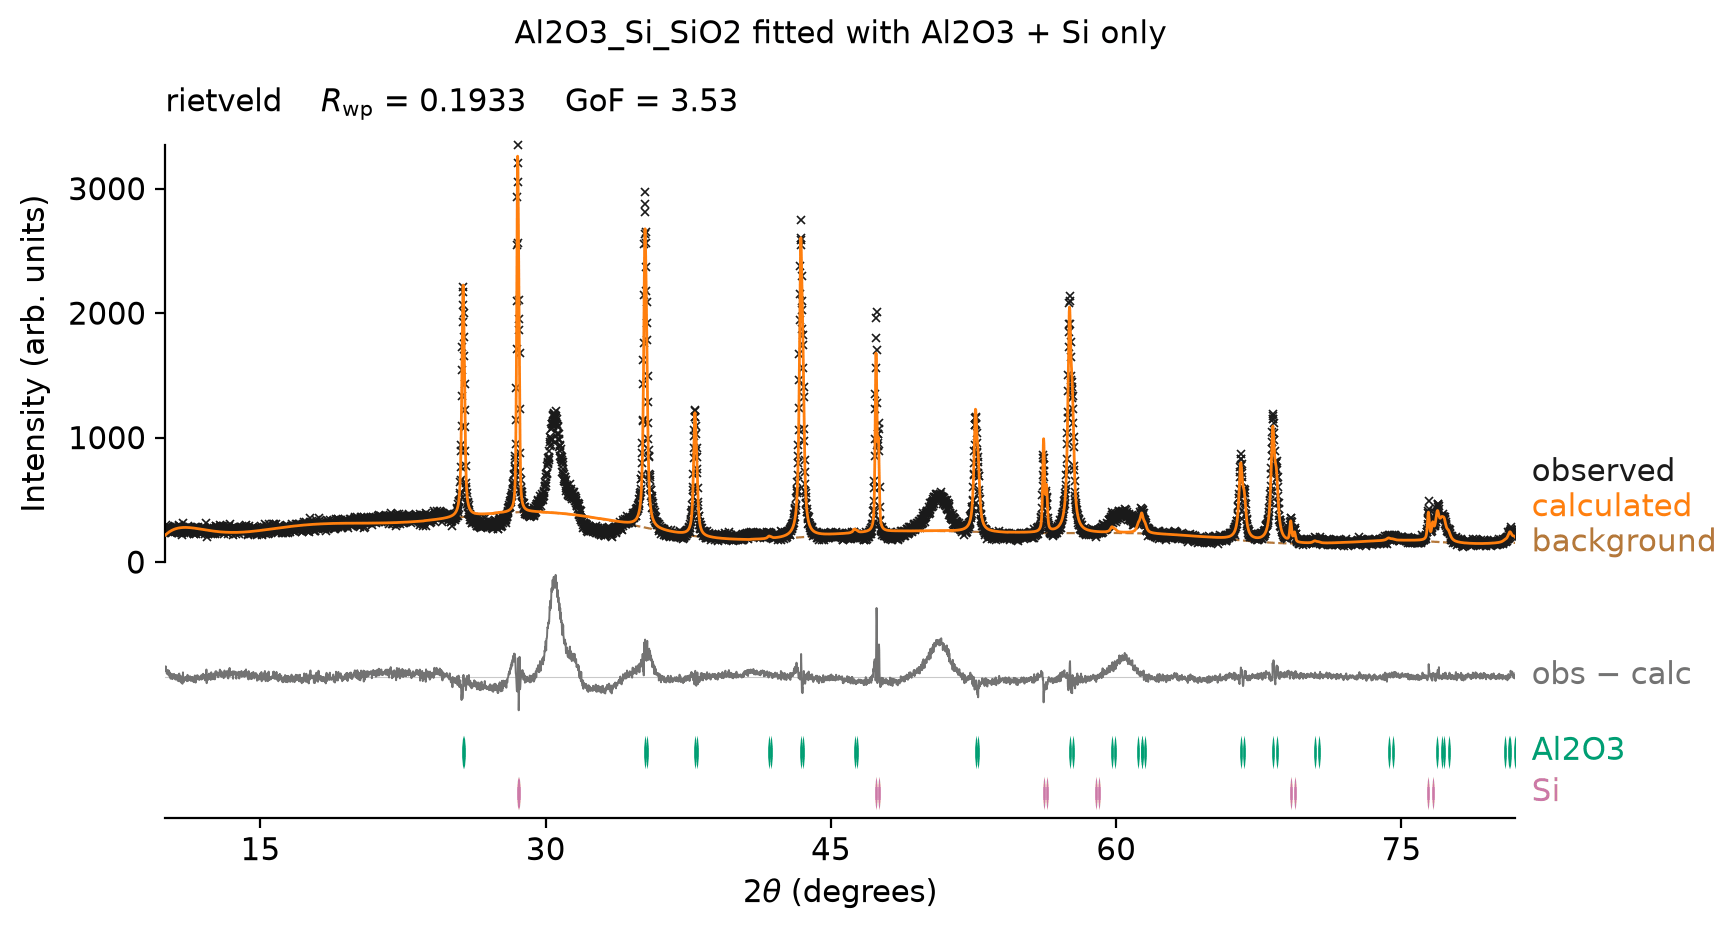

In [14]:
DATA3 = Path("../refinement examples/Al2O3_Si_SiO2")
data3 = rx.read_pattern(DATA3 / "Al2O3_Si_SiO2.raw")
LIMITS3 = (float(min(data3.two_theta)), float(max(data3.two_theta)))
inst3 = rx.load_instrument_profile("lab_profile.json")
inst3.background = rx.auto_background(data3, kind="chebyshev", two_theta_limits=LIMITS3)
ref3 = rx.Refinement(load_structure(), inst3)
res3 = ref3.fit(data3, plan="lab_sample_refine", two_theta_limits=LIMITS3)
rep3 = ref3.report(plan="lab_sample_refine")
print(f"GoF {res3.statistics.gof:.2f}, DW {res3.statistics.durbin_watson:.2f}; fractions:",
      {k: round(v, 1) for k, v in wt(res3).items()})
for a in rep3.suggested_actions:
    print(f"suggested: {a.kind} (confidence {a.confidence:.2f}): {a.rationale[:200]}...")
um = sorted(u.two_theta for u in rep3.unmatched if u.kind == "unmatched_obs")
print(f"{len(um)} unmatched observed points, in clusters around:",
      sorted({round(x) for x in um}))
rx.viz.plot_result(res3, figsize=(10, 4.5), dpi=110, title="Al2O3_Si_SiO2 fitted with Al2O3 + Si only")

rietx asks for an impurity phase at confidence 0.9. The unmatched intensity sits in **broad peaks near 30.5,
35.5, 50.6 and 60.4°**. Amorphous silica would give a single broad hump near 22°; there is at most a faint rise
in the background there. These broad peaks index on a face-centred cubic, fluorite-type cell with
a ≈ 5.08 Å: (111), (200), (220) and (311).

Compare the GSAS-II model of this scan. It added **quartz** for the SiO2, which refined to 0.36 wt% because
there is no quartz in the pattern, and it did not model the broad phase:

In [15]:
g3 = read_lst(DATA3 / "refinement" / "test_amorphous.lst")
print(f"GSAS-II test_amorphous: wR {g3['wR']:.3f}, GOF {g3['gof']}, Durbin-Watson {g3['durbin_watson']}")
for name, ph in g3["phases"].items():
    print(f"  {name:6s} wt% {100*ph['weight_fraction']:6.2f}   Uiso {ph['uiso']}")

GSAS-II test_amorphous: wR 0.302, GOF 5.5, Durbin-Watson 0.061
  Al2 O3 wt%  88.66   Uiso {'O1': -1.85421, 'Al1': -1.99372}
  Si     wt%  10.98   Uiso {'Si': -0.49524}
  O2 Si  wt%   0.36   Uiso {'O1': 0.0, 'Si1': 0.0}


GSAS-II's fit has GOF 5.5 and Durbin-Watson 0.06, and its displacement parameters went to **Uiso ≈ −1.9 Å²**
(Biso ≈ −150 Å²): the refinement was compensating for a phase that was not in the model. Now add a hypothetical
fluorite-type phase (Fm-3m, cation at 0,0,0 and O at ¼,¼,¼, scattering as Zr) and let it refine.

In [16]:
P = rx.Parameter
fluorite = rx.Phase(
    name="fluorite (ZrO2-like)", space_group="F m -3 m",
    cell=rx.Cell(a=P(value=5.09), b=P(value=5.09), c=P(value=5.09),
                 alpha=P(value=90.0), beta=P(value=90.0), gamma=P(value=90.0)),
    atoms=[rx.Atom(label="Zr", species="Zr4+", x=P(value=0.0), y=P(value=0.0), z=P(value=0.0), biso=P(value=0.5)),
           rx.Atom(label="O", species="O2-", x=P(value=0.25), y=P(value=0.25), z=P(value=0.25), biso=P(value=1.0))])
fluorite.lor_size.value = 1.0                   # start broad: the peaks are about 1° wide
structure4 = load_structure(); structure4.phases.append(fluorite)
inst4 = rx.load_instrument_profile("lab_profile.json")
inst4.background = rx.auto_background(data3, kind="chebyshev", two_theta_limits=LIMITS3)
ref4 = rx.Refinement(structure4, inst4)
res4 = ref4.fit(data3, plan="lab_sample_refine", two_theta_limits=LIMITS3)
rep4 = ref4.report(plan="lab_sample_refine")
print(f"GoF {res3.statistics.gof:.2f} -> {res4.statistics.gof:.2f}; unmatched observed points "
      f"{len(um)} -> {sum(u.kind == 'unmatched_obs' for u in rep4.unmatched)}")
print("fluorite a =", round(next(p.value for p in res4.parameters if p.path == "phases.2.cell.a"), 4), "Å")
print("fractions:", {k: round(v, 1) for k, v in wt(res4).items()})
print("still unmatched near:", sorted({round(u.two_theta, 1) for u in rep4.unmatched if u.kind == "unmatched_obs"}))
print()
show_diagnostics(res4)

GoF 3.53 -> 1.50; unmatched observed points 55 -> 8
fluorite a = 5.0958 Å
fractions: {'Al2O3': 72.3, 'Si': 12.8, 'fluorite (ZrO2-like)': 14.9}
still unmatched near: [28.1, 28.2, 28.3, 31.3, 31.4, 31.5, 31.6, 31.7]

[WARNING] BACKGROUND_ABSORPTION  phases.2.scale
     the background can reproduce most of phases.2.scale (R²=0.41)
[WARNING] BACKGROUND_ABSORPTION  phases.2.scale
     the background can reproduce most of phases.2.scale (R²=0.41)
[WARNING] BACKGROUND_ABSORPTION  phases.2.scale
     the background can reproduce most of phases.2.scale (R²=0.41)
[WARNING] BACKGROUND_ABSORPTION  phases.2.scale
     the background can reproduce most of phases.2.scale (R²=0.42)
[WARNING] BACKGROUND_ABSORPTION  phases.2.atoms.0.biso
     the background can reproduce most of phases.2.atoms.0.biso (R²=0.52)
[WARNING] BACKGROUND_ABSORPTION  phases.2.scale
     the background can reproduce most of phases.2.scale (R²=0.43)
[WARNING] BACKGROUND_ABSORPTION  phases.2.atoms.1.biso
     the background can re

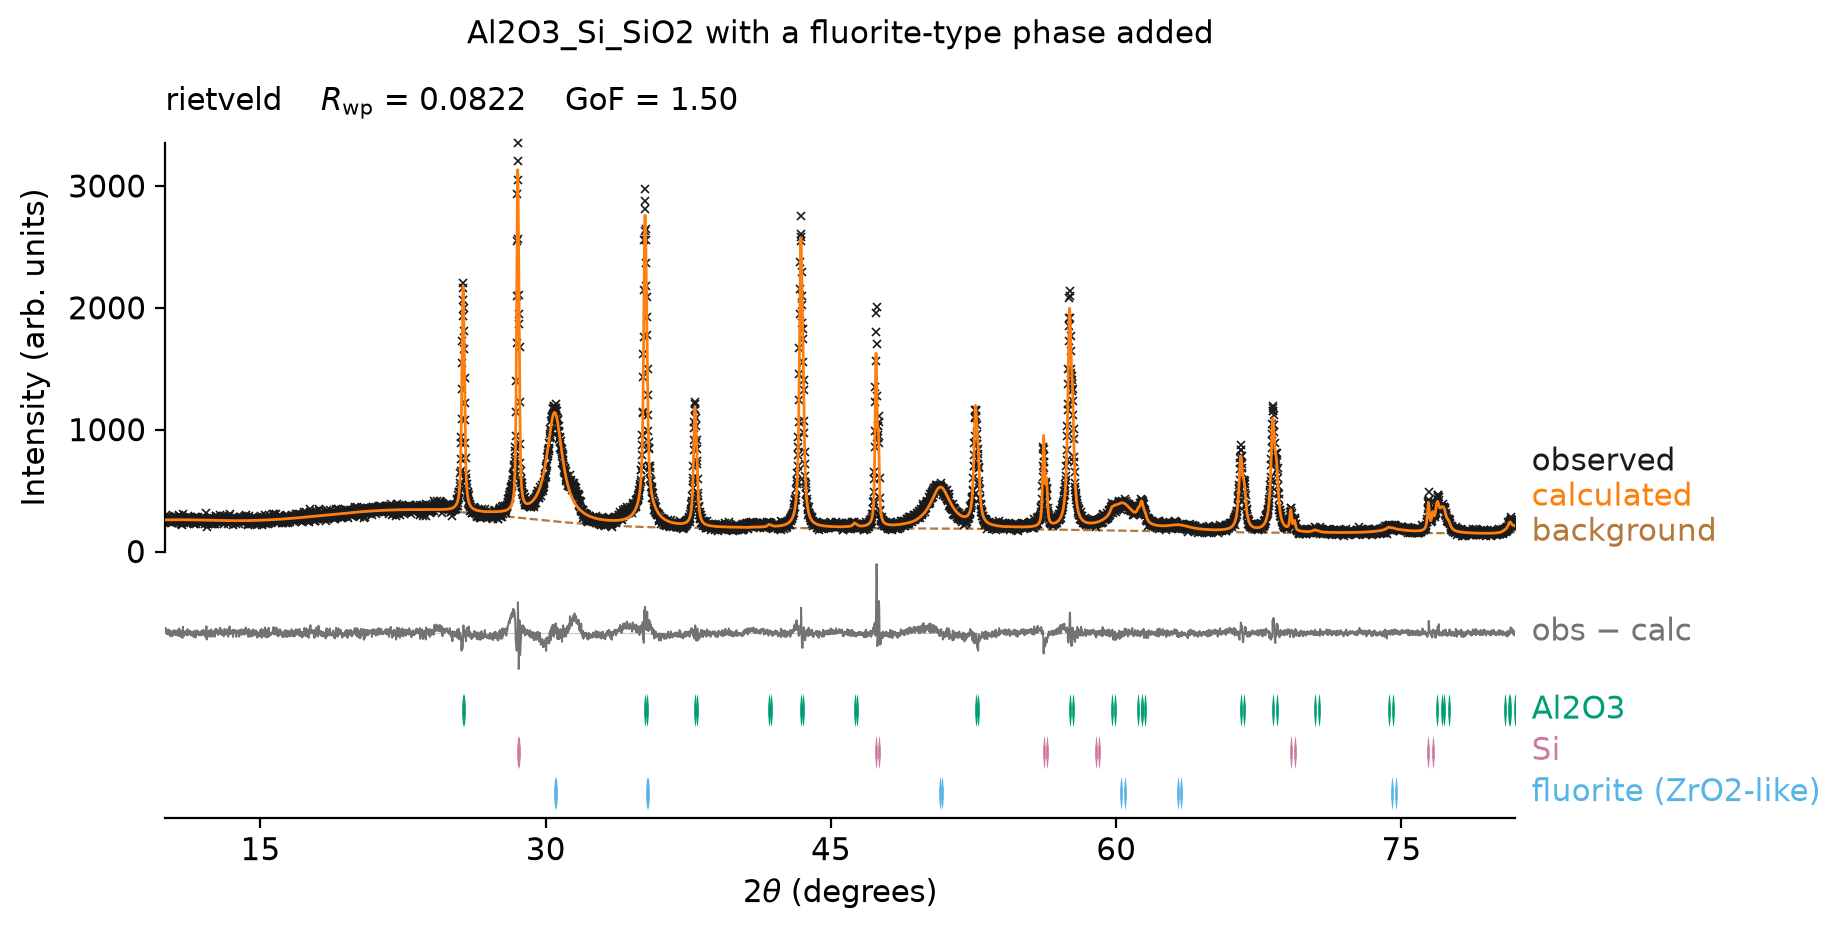

In [17]:
rx.viz.plot_result(res4, figsize=(10, 4.5), dpi=110, title="Al2O3_Si_SiO2 with a fluorite-type phase added")

Adding the fluorite phase drops GoF from 3.5 to 1.5 and removes most of the unmatched intensity. It refines to
a = 5.096 Å, a value typical of a stabilized (cubic or tetragonal) zirconia. The few points still unmatched sit
near **28.2° and 31.5°, the two strongest lines of monoclinic ZrO2**. A broad zirconia contribution with some
monoclinic ZrO2 is what wear debris from zirconia milling media looks like, so the most likely story is
contamination during grinding. That is a hypothesis: confirm it with the sample's preparation history or a
Zr-sensitive chemical analysis (XRF, EDS).

The diagnostics say what **not** to quote:

* **`BACKGROUND_ABSORPTION`** on the fluorite scale and Biso (R² 0.4 to 0.5): its peaks are so broad that the
  background can imitate them. Its 15 wt% is biased and is not a measurement.
* **`FLOOR_HIT`** on width terms again, as with the 90/10 sample: the LaB6 profile is too broad for this
  instrument.
* The sample displacement is exchangeable with the held zero shift: positions are not trustworthy at the
  0.01° level here.

**On amorphous SiO2**: the faint rise near 22° is consistent with a little amorphous silica, but it is carried
by the background, and with an unknown recipe and an internal standard (Si) that we have just shown reads
three times too low, no amorphous fraction can be measured from this pattern. Measuring amorphous content
needs a fine, well-characterized internal standard of known mass fraction.

Finally, the per-reflection test from section 5b on this second mount, measured on the same instrument:

In [18]:
print(" hkl         2θ      obs/calc   counting error")
for hkl, pos, q, e in si_reflection_ratios(ref4, res4):
    print(f" {str(hkl):10s}{pos:6.2f}    {q:6.2f}      ± {e:.2f}")

 hkl         2θ      obs/calc   counting error
 (1, 1, 1)  28.53      1.04      ± 0.01
 (2, 2, 0)  47.38      1.10      ± 0.01
 (3, 1, 1)  56.19      0.93      ± 0.01
 (4, 0, 0)  69.18      1.02      ± 0.04
 (3, 3, 1)  76.42      1.03      ± 0.03


Here every Si reflection sits within 10 % of its calculated intensity. So the large scatter in the 90/10 mount
is not a property of the Si structure model, the profile, or the instrument: it belongs to that particular
specimen, which is what poor particle statistics predicts. (This mount's Si/Al2O3 ratio is also far higher than
the 90/10 mount's, but without its recipe we cannot say which one is closer to its weighed value.)

## Summary

| Question | Answer from the data |
|---|---|
| Do rietx and GSAS-II agree? | Yes: 96.8 / 3.2 wt% against 96.76 / 3.24 wt% |
| Is that answer stable to background and instrument choices? | Yes, within 0.05 wt% |
| Is it stable to the displacement parameters? | No: holding B at physical values gives Si ≈ 3.6 wt% (a 0.5 wt% systematic) |
| Is the LaB6 profile right for this instrument? | No: different instrument; Si peaks are narrower than the profile (`FLOOR_HIT`) |
| Amorphous content? | Ruled out as the main cause (it would raise the Si reading, not lower it) |
| Microabsorption? | Too small: µ(Si) ≈ µ(Al2O3) for Cu Kα; +0.6 wt% even for 50 µm Si |
| Particle statistics? | Supported: Si reflections scatter 0.6 to 2.1× calculated in the unspun 90/10 mount, but sit within 10 % in a second mount |
| Al2O3_Si_SiO2 | Missing phase is broad fluorite-type ZrO2-like material (plus some monoclinic), not quartz |

**What to do in the lab**: spin the specimen; use fine Si (a few µm) or a certified fine standard; prepare and
measure several independent mounts and report their spread; for amorphous content, add a known mass of a
fine internal standard.

In [19]:
print(result.provenance)

Provenance
  package_version: '1.9.0'
  schema_version: '0.55'
  backend: 'numpy'
  dtype: 'float64'
  solver: 'lm'
  report_thresholds_version: '1.12'
  created_utc: '2026-10-23T22:01:04Z'
